# Лабораторная работа 3. <br/> Методы приближения функций. Численное дифференцирование и интегрирование


## Общий функционал


In [1]:
import math
from bisect import bisect_left, bisect_right
from dataclasses import dataclass

import matplotlib.pyplot as plt


In [2]:
def fmt(value):
    return f"{value:.12g}" if isinstance(value, float) else str(value)


def print_table(headers, rows):
    rows = [[fmt(value) for value in row] for row in rows]
    widths = [max(len(str(header)), *(len(row[i]) for row in rows))
              for i, header in enumerate(headers)]
    def line(row):
        return " | ".join(str(value).rjust(width) for value, width in zip(row, widths))
    print(line(headers))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(line(row))


def multiply_linear(coefficients, root):
    """Умножить многочлен на (x - root)."""
    result = [0.0] * (len(coefficients) + 1)
    for i, coefficient in enumerate(coefficients):
        result[i] -= root * coefficient
        result[i + 1] += coefficient
    return result


def polynomial_value(coefficients, x):
    value = 0.0
    for coefficient in reversed(coefficients):
        value = value * x + coefficient
    return value


def shift_text(root):
    if root == 0:
        return "x"
    return f"(x {'-' if root > 0 else '+'} {fmt(abs(root))})"


def sum_text(terms):
    """Оформить сумму пар (числовой коэффициент, символьный множитель)."""
    result = ""
    for coefficient, factor in terms:
        if coefficient == 0:
            continue
        magnitude = fmt(abs(coefficient))
        term = magnitude + (f" * {factor}" if factor else "")
        if not result:
            result = ("-" if coefficient < 0 else "") + term
        else:
            result += (" - " if coefficient < 0 else " + ") + term
    return result or "0"


def polynomial_text(coefficients, variable="x"):
    return sum_text((value, "" if i == 0 else variable if i == 1 else f"{variable}^{i}")
                    for i, value in enumerate(coefficients))


def solve_linear_system(matrix, rhs):
    """Метод Гаусса с выбором ведущей строки по относительной величине элемента."""
    n = len(rhs)
    a = [list(map(float, row)) + [float(value)] for row, value in zip(matrix, rhs)]
    scales = [max(map(abs, row)) for row in matrix]
    for k in range(n):
        pivot = max(range(k, n), key=lambda i: abs(a[i][k]) / scales[i])
        a[k], a[pivot] = a[pivot], a[k]
        scales[k], scales[pivot] = scales[pivot], scales[k]
        for i in range(k + 1, n):
            multiplier = a[i][k] / a[k][k]
            a[i][k] = 0.0
            for j in range(k + 1, n + 1):
                a[i][j] -= multiplier * a[k][j]
    solution = [0.0] * n
    for i in range(n - 1, -1, -1):
        solution[i] = (a[i][n] - math.fsum(a[i][j] * solution[j]
                                         for j in range(i + 1, n))) / a[i][i]
    return solution


def solve_tridiagonal(lower, diagonal, upper, rhs):
    """Прогонка: хранить только три диагонали, прямой и обратный ход."""
    n = len(diagonal)
    p, q = [0.0] * n, [0.0] * n
    for i in range(n):
        denominator = diagonal[i] + (lower[i - 1] * p[i - 1] if i else 0.0)
        scale = max(abs(diagonal[i]), abs(lower[i - 1]) if i else 0.0,
                    abs(upper[i]) if i < n - 1 else 0.0)
        if i < n - 1:
            p[i] = -upper[i] / denominator
        q[i] = (rhs[i] - (lower[i - 1] * q[i - 1] if i else 0.0)) / denominator
    result = [0.0] * n
    result[-1] = q[-1]
    for i in range(n - 2, -1, -1):
        result[i] = p[i] * result[i + 1] + q[i]
    return result


def sample_points(left, right, count=601):
    return [left + (right - left) * i / (count - 1) for i in range(count)]


def finish_plot(axis, title):
    axis.set(title=title, xlabel="x", ylabel="y")
    axis.grid(True, alpha=0.3)
    axis.legend()
    axis.figure.tight_layout()


## Задание 3.1. Интерполяционные многочлены Лагранжа и Ньютона

### Условие

Используя таблицу значений $Y_i$ функции $y = f(x)$, вычисленных в точках
$X_i$, $i = 0,\ldots,3$ построить интерполяционные многочлены Лагранжа и Ньютона,
проходящие через точки $\{X_i, Y_i\}$. Вычислить значение погрешности интерполяции
в точке $X^*$.

### Требования лаборанта

Необходимо реализовать оба метода.

В результате работы программы необходимо вывести:

1. Исходные узлы интерполяции $x_i$ и значения функции $y_i$.
2. Интерполяционный многочлен Лагранжа.
3. Таблицу разделённых разностей.
4. Интерполяционный многочлен Ньютона.
5. Значение многочлена Лагранжа в заданной точке $x^*$.
6. Значение многочлена Ньютона в заданной точке $x^*$.
7. Точное значение функции $f(x^*)$.
8. Абсолютную погрешность интерполяции.
9. Разность между результатами методов Лагранжа и Ньютона.

Также необходимо построить общий график, на котором должны быть показаны:

- исходная функция;
- многочлен Лагранжа;
- многочлен Ньютона;
- узлы интерполяции;
- заданная точка $x^*$.


### Входные данные

$y = \operatorname{tg}(x)$

а) $X_i = 0,\ \frac{\pi}{8},\ \frac{2\pi}{8},\ \frac{3\pi}{8}$

б) $X_i = 0,\ \frac{\pi}{8},\ \frac{\pi}{3},\ \frac{3\pi}{8}$

$X^* = \frac{3\pi}{16}$


In [3]:
data1 = {
    "function": math.tan,
    "x_star": 3 * math.pi / 16,
    "node_sets": [
        {"name": "а", "x": [0, math.pi / 8, 2 * math.pi / 8, 3 * math.pi / 8]},
        {"name": "б", "x": [0, math.pi / 8, math.pi / 3, 3 * math.pi / 8]},
    ],
}


### Реализация

Лагранж (3.5), разделённые разности (3.7), Ньютон (3.8).



Набор узлов а

i |            x_i |   y_i = f(x_i)
--+----------------+---------------
0 |              0 |              0
1 | 0.392699081699 | 0.414213562373
2 | 0.785398163397 |              1
3 |   1.1780972451 |  2.41421356237

Многочлен Лагранжа (3.5):
L(x) = 3.41990988021 * x * (x - 0.785398163397) * (x - 1.1780972451) - 8.2563928149 * x * (x - 0.392699081699) * (x - 1.1780972451) + 6.64423183667 * x * (x - 0.392699081699) * (x - 0.785398163397)
В степенном виде:
L(x) = 1.3938880093 * x - 1.5734170636 * x^2 + 1.80774890198 * x^3

Таблица разделённых разностей:
           x_i |         f[x_i] |     порядок 1 |      порядок 2 |     порядок 3
---------------+----------------+---------------+----------------+--------------
             0 |              0 | 1.05478617516 | 0.556286937652 | 1.80774890198
0.392699081699 | 0.414213562373 | 1.49169291431 |   2.6859909389 |              
0.785398163397 |              1 | 3.60126526463 |                |              
  1.1780972451 |  2.4

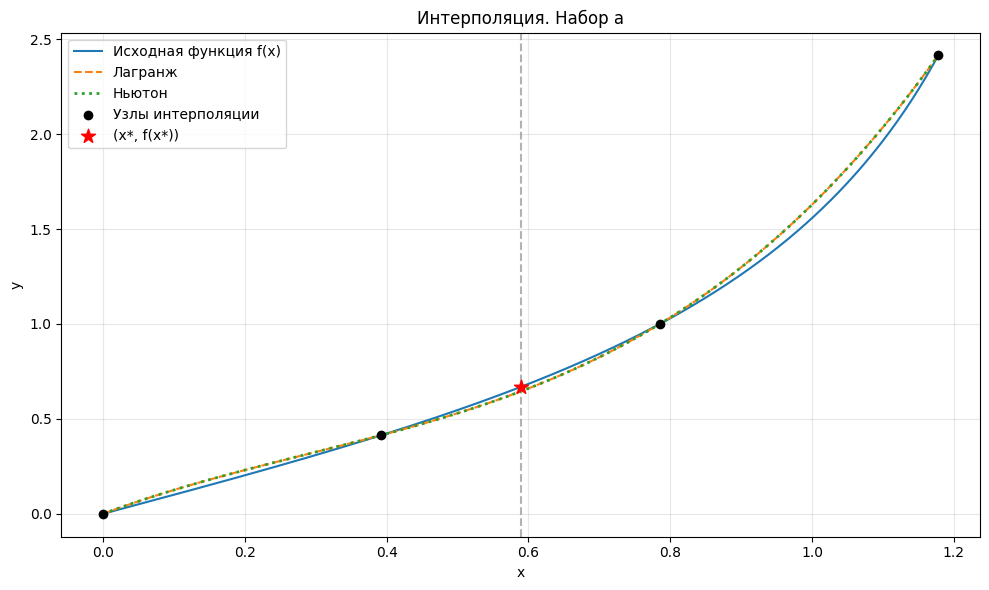

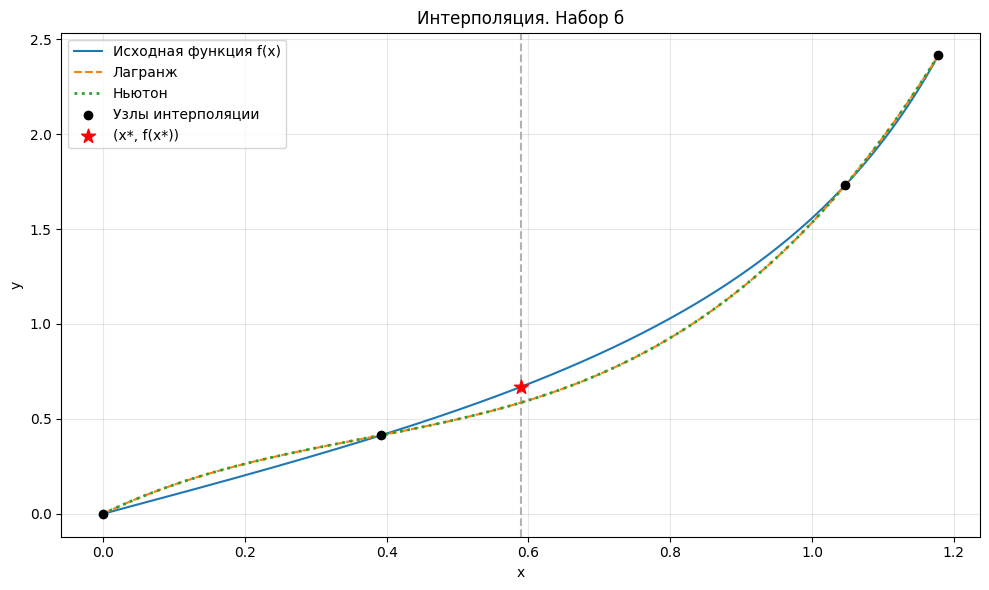

In [4]:
def lagrange_weights(x, y):
    # f_i / произведение (x_i - x_j), j != i, в формуле (3.5).
    return [y[i] / math.prod(x[i] - x[j] for j in range(len(x)) if j != i)
            for i in range(len(x))]


def lagrange_value(x, y, point):
    weights = lagrange_weights(x, y)
    return math.fsum(weight * math.prod(point - x[j] for j in range(len(x)) if j != i)
                     for i, weight in enumerate(weights))


def lagrange_polynomial(x, y):
    coefficients = [0.0] * len(x)
    for i, weight in enumerate(lagrange_weights(x, y)):
        basis = [1.0]
        for j, node in enumerate(x):
            if i != j:
                basis = multiply_linear(basis, node)
        for power, coefficient in enumerate(basis):
            coefficients[power] += weight * coefficient
    return coefficients


def divided_differences(x, y):
    table = [[value] for value in y]
    # table[i][order] = f(x_i, ..., x_(i+order)), рекурсия (3.7).
    for order in range(1, len(x)):
        for i in range(len(x) - order):
            table[i].append((table[i + 1][order - 1] - table[i][order - 1])
                            / (x[i + order] - x[i]))
    return table


def newton_value(x, table, point):
    # Вложенная форма (3.8) не требует раскрывать произведения.
    value = table[0][-1]
    for i in range(len(x) - 2, -1, -1):
        value = table[0][i] + (point - x[i]) * value
    return value


def newton_polynomial(x, table):
    result = [0.0] * len(x)
    basis = [1.0]
    for order, coefficient in enumerate(table[0]):
        for power, value in enumerate(basis):
            result[power] += coefficient * value
        basis = multiply_linear(basis, x[order])
    return result


def print_interpolation_result(name, x, y, point, exact, table):
    print(f"\nНабор узлов {name}\n")
    print_table(["i", "x_i", "y_i = f(x_i)"],
                [(i, node, value) for i, (node, value) in enumerate(zip(x, y))])
    lagrange_terms = [(weight, " * ".join(shift_text(node) for j, node in enumerate(x) if i != j))
                      for i, weight in enumerate(lagrange_weights(x, y))]
    print(f"\nМногочлен Лагранжа (3.5):\nL(x) = {sum_text(lagrange_terms)}")
    print(f"В степенном виде:\nL(x) = {polynomial_text(lagrange_polynomial(x, y))}")
    print("\nТаблица разделённых разностей:")
    headers = ["x_i", "f[x_i]"] + [f"порядок {i}" for i in range(1, len(x))]
    print_table(headers, [[node] + row + [""] * (len(x) - len(row)) for node, row in zip(x, table)])
    newton_terms = [(value, " * ".join(shift_text(node) for node in x[:order]))
                    for order, value in enumerate(table[0])]
    print(f"\nМногочлен Ньютона (3.8):\nN(x) = {sum_text(newton_terms)}")
    print(f"В степенном виде:\nN(x) = {polynomial_text(newton_polynomial(x, table))}")
    lagrange = lagrange_value(x, y, point)
    newton = newton_value(x, table, point)
    print(f"\nx* = {fmt(point)}")
    print(f"L(x*) = {fmt(lagrange)}")
    print(f"N(x*) = {fmt(newton)}")
    print(f"Точное значение f(x*) = {fmt(exact)}")
    print(f"Абсолютная погрешность Лагранжа = {fmt(abs(lagrange - exact))}")
    print(f"Абсолютная погрешность Ньютона = {fmt(abs(newton - exact))}")
    print(f"Разность L(x*) - N(x*) = {fmt(lagrange - newton)}")
    print(f"Модуль разности = {fmt(abs(lagrange - newton))}")


def plot_interpolation(plt, name, function, x, y, point, table):
    grid = sample_points(min(min(x), point), max(max(x), point))
    # Для единственного узла задаём ненулевую ширину только области графика.
    if grid[0] == grid[-1]:
        grid = sample_points(point - 1, point + 1)
    exact = []
    for node in grid:
        try:
            exact.append(function(node))
        except ValueError:
            exact.append(math.nan)
    _, axis = plt.subplots(figsize=(10, 6))
    axis.plot(grid, exact, label="Исходная функция f(x)")
    axis.plot(grid, [lagrange_value(x, y, node) for node in grid], "--", label="Лагранж")
    axis.plot(grid, [newton_value(x, table, node) for node in grid], ":", linewidth=2, label="Ньютон")
    axis.scatter(x, y, color="black", zorder=5, label="Узлы интерполяции")
    axis.axvline(point, color="gray", linestyle="--", alpha=0.6)
    axis.scatter([point], [function(point)], color="red", marker="*", s=110,
                 zorder=6, label="(x*, f(x*))")
    finish_plot(axis, f"Интерполяция. Набор {name}")


def main(data):
    function = data['function']
    point = data['x_star']
    sets = data['node_sets']
    results = []
    for i, item in enumerate(sets, 1):
        x = item['x']
        y = [function(node) for node in x]
        table = divided_differences(x, y)
        name = str(item.get('name', i))
        print_interpolation_result(name, x, y, point, function(point), table)
        results.append((name, x, y, table))
    for name, x, y, table in results:
        plot_interpolation(plt, name, function, x, y, point, table)
    plt.show()


main(data1)


## Задание 3.2. Кубический сплайн

### Условие

Построить кубический сплайн для функции, заданной в узлах интерполяции,
предполагая, что сплайн имеет нулевую кривизну при $x = x_0$ и $x = x_4$.
Вычислить значение функции в точке $x = X^*$.

### Требования лаборанта

В результате работы программы необходимо вывести:

1. Исходные узлы и значения функции.
2. Коэффициенты $a_i$, $b_i$, $c_i$, $d_i$ для каждого участка сплайна.
3. Интервал, на котором действует каждый полученный многочлен.
4. Значение сплайна в заданной точке $x^*$.
5. Номер интервала, содержащего точку $x^*$.
6. Проверку прохождения сплайна через исходные узлы.
7. Значения второй производной на концах интервала для проверки граничных условий.

Также необходимо построить график, на котором должны быть показаны:

- исходные узлы;
- все участки кубического сплайна;
- заданная точка $(x^*, S(x^*))$.


### Входные данные

$X^* = 1.5$

| $i$ | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| $x_i$ | 0.0 | 0.9 | 1.8 | 2.7 | 3.6 |
| $f_i$ | 0.0 | 0.36892 | 0.85408 | 1.7856 | 6.3138 |


In [5]:
data2 = {
    "x": [0.0, 0.9, 1.8, 2.7, 3.6],
    "y": [0.0, 0.36892, 0.85408, 1.7856, 6.3138],
    "x_star": 1.5,
}


### Реализация

Естественный кубический сплайн: (3.11), система (3.13), коэффициенты (3.14).


Исходные данные:
i | x_i |     f_i
--+-----+--------
0 |   0 |       0
1 | 0.9 | 0.36892
2 | 1.8 | 0.85408
3 | 2.7 |  1.7856
4 | 3.6 |  6.3138

Коэффициенты S_i(x) = a_i + b_i*t + c_i*t^2 + d_i*t^3, t = x - x_(i-1):
i |   Интервал |     a_i |            b_i |             c_i |             d_i
--+------------+---------+----------------+-----------------+----------------
1 |   [0, 0.9] |       0 | 0.339378571429 |               0 | 0.0870772094846
2 | [0.9, 1.8] | 0.36892 | 0.550976190476 |  0.235108465608 | -0.275934744268
3 | [1.8, 2.7] | 0.85408 |        0.30365 | -0.509915343915 |   1.46950127376
4 | [2.7, 3.6] |  1.7856 |  2.95669047619 |   3.45773809524 |  -1.28064373898

Многочлены участков:
S_1(x) = 0.339378571429 * x + 0.0870772094846 * x^3, x в [0, 0.9]
S_2(x) = 0.36892 + 0.550976190476 * (x - 0.9) + 0.235108465608 * (x - 0.9)^2 - 0.275934744268 * (x - 0.9)^3, x в [0.9, 1.8]
S_3(x) = 0.85408 + 0.30365 * (x - 1.8) - 0.509915343915 * (x - 1.8)^2 + 1.46950127376 * (x - 1.8)^3, x в

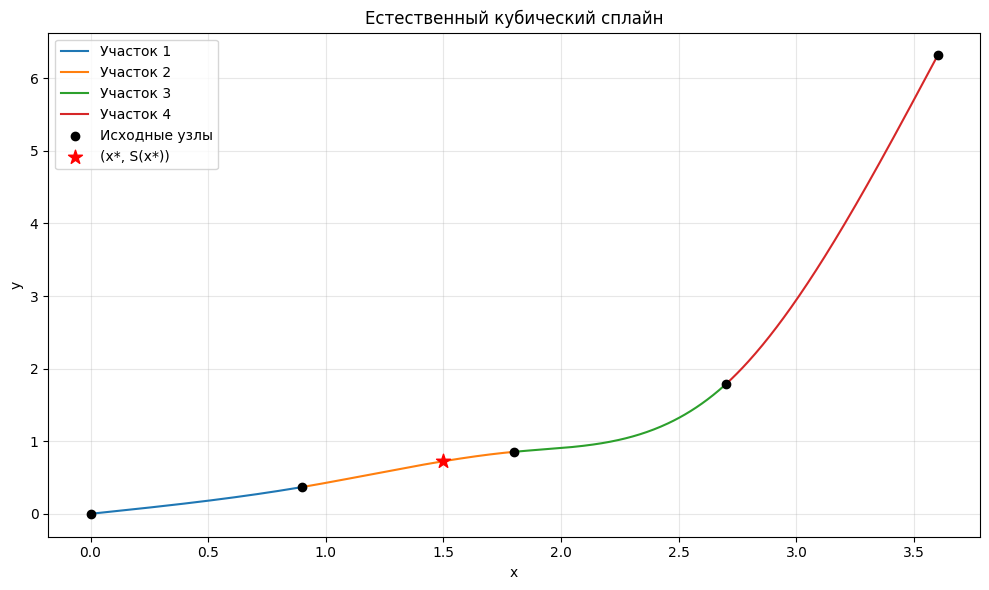

In [6]:
@dataclass(frozen=True)
class Segment:
    left: float
    right: float
    a: float
    b: float
    c: float
    d: float

    def value(self, x):
        t = x - self.left
        return self.a + t * (self.b + t * (self.c + t * self.d))

    def first(self, x):
        t = x - self.left
        return self.b + 2 * self.c * t + 3 * self.d * t * t

    def second(self, x):
        return 2 * self.c + 6 * self.d * (x - self.left)


def natural_spline(x, y):
    n = len(x) - 1
    h = [x[i + 1] - x[i] for i in range(n)]
    # c[i] — коэффициент при квадрате на участке с левым концом x[i].
    # В методичке номера участков начинаются с 1: наше c[i] соответствует c_(i+1).
    # Дополнительное c[n] = 0 задаёт S''(x[n]) = 0; c[0] = 0 задаёт S''(x[0]) = 0.
    c = [0.0] * (n + 1)
    if n > 1:
        diagonal = [2 * (h[i - 1] + h[i]) for i in range(1, n)]
        rhs = [3 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
               for i in range(1, n)]
        # Система (3.13) трёхдиагональная, поэтому используем свою прогонку.
        c[1:n] = solve_tridiagonal(h[1:n - 1], diagonal, h[1:n - 1], rhs)
    segments = []
    for i in range(n):
        a = y[i]
        b = (y[i + 1] - y[i]) / h[i] - h[i] * (2 * c[i] + c[i + 1]) / 3
        d = (c[i + 1] - c[i]) / (3 * h[i])
        segments.append(Segment(x[i], x[i + 1], a, b, c[i], d))
    return segments


def interval_index(x, point):
    # В общем узле выбираем правый участок, на последнем узле — последний.
    return min(bisect_right(x, point) - 1, len(x) - 2)


def spline_value(x, segments, point):
    return segments[interval_index(x, point)].value(point)


def continuity_errors(segments):
    errors = [0.0, 0.0, 0.0]
    for left, right in zip(segments, segments[1:]):
        point = left.right
        for i, method in enumerate(("value", "first", "second")):
            errors[i] = max(errors[i], abs(getattr(left, method)(point)
                                           - getattr(right, method)(point)))
    return errors


def plot_spline(plt, x, y, segments, point):
    _, axis = plt.subplots(figsize=(10, 6))
    for i, segment in enumerate(segments, 1):
        grid = sample_points(segment.left, segment.right, count=151)
        axis.plot(grid, [segment.value(node) for node in grid], label=f"Участок {i}")
    axis.scatter(x, y, color="black", zorder=5, label="Исходные узлы")
    axis.scatter([point], [spline_value(x, segments, point)], color="red", marker="*",
                 s=110, zorder=6, label="(x*, S(x*))")
    finish_plot(axis, "Естественный кубический сплайн")


def main(data):
    x, y = (data['x'], data['y'])
    point = data['x_star']
    segments = natural_spline(x, y)
    print('Исходные данные:')
    print_table(['i', 'x_i', 'f_i'], [(i, a, b) for i, (a, b) in enumerate(zip(x, y))])
    print('\nКоэффициенты S_i(x) = a_i + b_i*t + c_i*t^2 + d_i*t^3, t = x - x_(i-1):')
    print_table(['i', 'Интервал', 'a_i', 'b_i', 'c_i', 'd_i'], [(i, f'[{fmt(s.left)}, {fmt(s.right)}]', s.a, s.b, s.c, s.d) for i, s in enumerate(segments, 1)])
    print('\nМногочлены участков:')
    for i, segment in enumerate(segments, 1):
        expression = polynomial_text([segment.a, segment.b, segment.c, segment.d], shift_text(segment.left))
        print(f'S_{i}(x) = {expression}, x в [{fmt(segment.left)}, {fmt(segment.right)}]')
    index = interval_index(x, point)
    print(f'\nx* = {fmt(point)}; номер интервала: {index + 1}')
    print(f'S(x*) = {fmt(spline_value(x, segments, point))}')
    print('\nПроверка прохождения через исходные узлы:')
    values = [spline_value(x, segments, node) for node in x]
    print_table(['i', 'x_i', 'f_i', 'S(x_i)', '|S(x_i) - f_i|'], [(i, node, value, actual, abs(actual - value)) for i, (node, value, actual) in enumerate(zip(x, y, values))])
    print(f"\nS''({fmt(x[0])}) = {fmt(segments[0].second(x[0]))}")
    print(f"S''({fmt(x[-1])}) = {fmt(segments[-1].second(x[-1]))}")
    print('Максимальные расхождения в стыках:')
    for name, error in zip(('S', "S'", "S''"), continuity_errors(segments)):
        print(f'{name}: {fmt(error)}')
    plot_spline(plt, x, y, segments, point)
    plt.show()


main(data2)


## Задание 3.3. Метод наименьших квадратов

### Условие

Для таблично заданной функции путем решения нормальной системы МНК найти
приближающие многочлены a) 1-ой и б) 2-ой степени. Для каждого из приближающих
многочленов вычислить сумму квадратов ошибок. Построить графики приближаемой
функции и приближающих многочленов.

### Требования лаборанта

Необходимо построить приближающие многочлены первой, второй и третьей степени.

В результате работы программы необходимо вывести:

1. Коэффициенты многочлена первой степени.
2. Коэффициенты многочлена второй степени.
3. Коэффициенты многочлена третьей степени.
4. Полученные многочлены $P_1(x)$, $P_2(x)$ и $P_3(x)$ в явном виде.
5. Значения $\mathrm{MSE}_1$, $\mathrm{MSE}_2$ и $\mathrm{MSE}_3$, рассчитанные по всем исходным точкам.
6. Сравнение полученных ошибок и указание многочлена, который лучше приближает исходные данные.

Также необходимо построить общий график, на котором должны быть показаны:

- исходные данные в виде отдельных точек;
- многочлен первой степени;
- многочлен второй степени;
- многочлен третьей степени.


### Входные данные

| $i$ | 0 | 1 | 2 | 3 | 4 | 5 |
| --- | --- | --- | --- | --- | --- | --- |
| $x_i$ | -0.9 | 0.0 | 0.9 | 1.8 | 2.7 | 3.6 |
| $y_i$ | -0.36892 | 0.0 | 0.36892 | 0.85408 | 1.7856 | 6.3138 |


In [7]:
data3 = {
    "x": [-0.9, 0.0, 0.9, 1.8, 2.7, 3.6],
    "y": [-0.36892, 0.0, 0.36892, 0.85408, 1.7856, 6.3138],
    "degrees": [1, 2, 3],
}


### Реализация

Нормальная система МНК (3.17), решаемая собственным методом Гаусса.


Исходные данные:
i |  x_i |      y_i
--+------+---------
0 | -0.9 | -0.36892
1 |    0 |        0
2 |  0.9 |  0.36892
3 |  1.8 |  0.85408
4 |  2.7 |   1.7856
5 |  3.6 |   6.3138

Многочлен степени 1:
Коэффициент |       Значение
------------+---------------
        a_0 | -0.19013447619
        a_1 |  1.24620825397
P_1(x) = -0.19013447619 + 1.24620825397 * x

Многочлен степени 2:
Коэффициент |        Значение
------------+----------------
        a_0 | -0.464501142857
        a_1 | -0.125625079365
        a_2 |  0.508086419753
P_2(x) = -0.464501142857 - 0.125625079365 * x + 0.508086419753 * x^2

Многочлен степени 3:
Коэффициент |        Значение
------------+----------------
        a_0 |  0.273367301587
        a_1 |  0.206220517343
        a_2 | -0.467930041152
        a_3 |  0.240991718742
P_3(x) = 0.273367301587 + 0.206220517343 * x - 0.467930041152 * x^2 + 0.240991718742 * x^3

Сравнение ошибок по всем исходным точкам:
Степень | Сумма квадратов ошибок |             MSE
--------+----

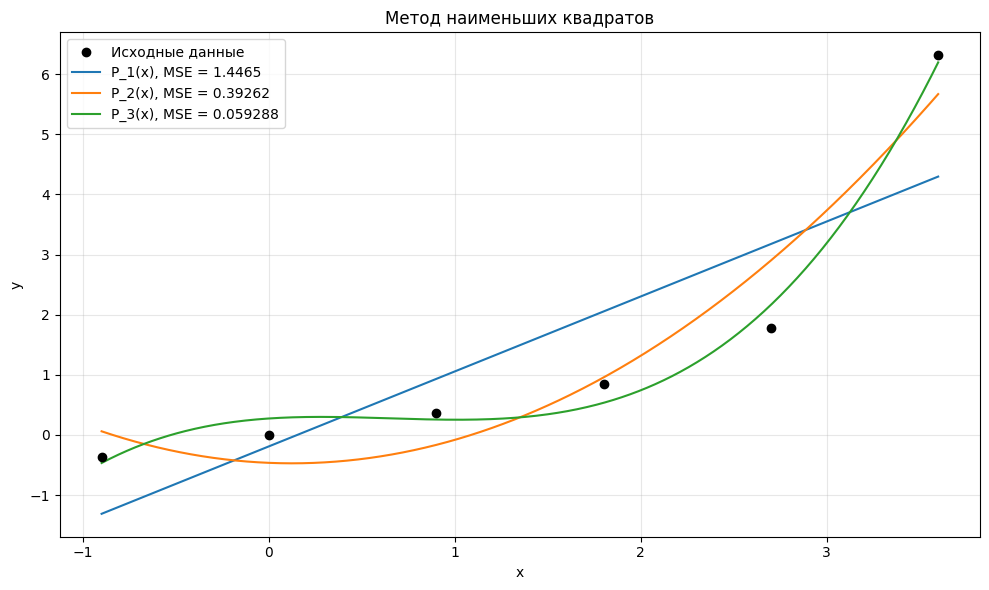

In [8]:
def least_squares(x, y, degree):
    # (3.17): A[k][i] = sum(x_j**(k+i)), b[k] = sum(y_j*x_j**k).
    powers = [math.fsum(node ** power for node in x) for power in range(2 * degree + 1)]
    matrix = [[powers[k + i] for i in range(degree + 1)] for k in range(degree + 1)]
    rhs = [math.fsum(value * node ** k for node, value in zip(x, y)) for k in range(degree + 1)]
    return solve_linear_system(matrix, rhs)


def squared_errors(x, y, coefficients):
    sse = math.fsum((polynomial_value(coefficients, node) - value) ** 2
                    for node, value in zip(x, y))
    return sse, sse / len(x)


def plot_approximation(plt, x, y, results):
    grid = sample_points(min(x), max(x))
    _, axis = plt.subplots(figsize=(10, 6))
    axis.scatter(x, y, color="black", zorder=5, label="Исходные данные")
    for degree, coefficients, _, mse in results:
        axis.plot(grid, [polynomial_value(coefficients, node) for node in grid],
                  label=f"P_{degree}(x), MSE = {mse:.5g}")
    finish_plot(axis, "Метод наименьших квадратов")


def main(data):
    x, y = (data['x'], data['y'])
    degrees = data['degrees']
    print('Исходные данные:')
    print_table(['i', 'x_i', 'y_i'], [(i, a, b) for i, (a, b) in enumerate(zip(x, y))])
    results = []
    for degree in degrees:
        coefficients = least_squares(x, y, degree)
        sse, mse = squared_errors(x, y, coefficients)
        results.append((degree, coefficients, sse, mse))
        print(f'\nМногочлен степени {degree}:')
        print_table(['Коэффициент', 'Значение'], [(f'a_{i}', c) for i, c in enumerate(coefficients)])
        print(f'P_{degree}(x) = {polynomial_text(coefficients)}')
    print('\nСравнение ошибок по всем исходным точкам:')
    print_table(['Степень', 'Сумма квадратов ошибок', 'MSE'], [(degree, sse, mse) for degree, _, sse, mse in results])
    minimum = min((row[3] for row in results))
    winners = [f'P_{degree}' for degree, _, _, mse in results if math.isclose(mse, minimum, rel_tol=1e-09, abs_tol=1e-12)]
    print(f"Минимальная MSE на исходных точках: {', '.join(winners)}.")
    plot_approximation(plt, x, y, results)
    plt.show()


main(data3)


## Задание 3.4. Численное дифференцирование

### Условие

Вычислить первую и вторую производную от таблично заданной функции
$y_i = f(x_i)$, $i = 0,1,2,3,4$ в точке $x = X^*$.

### Требования лаборанта

В результате работы программы необходимо вывести:

1. Исходную таблицу значений функции.
2. Точку, в которой выполняется вычисление.
3. Узлы таблицы, использованные при вычислении производных.
4. Значение первой производной.
5. Значение второй производной.


### Входные данные

$X^* = 2.0$

| $i$ | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| $x_i$ | 1.0 | 1.5 | 2.0 | 2.5 | 3.0 |
| $y_i$ | 0.0 | 0.40547 | 0.69315 | 0.91629 | 1.0986 |


In [9]:
data4 = {
    "x": [1.0, 1.5, 2.0, 2.5, 3.0],
    "y": [0.0, 0.40547, 0.69315, 0.91629, 1.0986],
    "x_star": 2.0,
}


### Реализация

Производные локального квадратичного многочлена (3.24), (3.25); линейные оценки (3.22).


In [10]:
def local_derivatives(x, y, point):
    # В узле используем соседей слева и справа, как в примере 3.5.
    # Между узлами берём левый узел, правый и следующий за ним.
    # У границ сдвигаем тройку внутрь таблицы.
    start = max(0, min(bisect_left(x, point) - 1, len(x) - 3))
    x0, x1, x2 = x[start:start + 3]
    y0, y1, y2 = y[start:start + 3]
    first_difference = (y1 - y0) / (x1 - x0)
    next_difference = (y2 - y1) / (x2 - x1)
    second_difference = (next_difference - first_difference) / (x2 - x0)
    # Общие формулы верны и для неравномерной сетки.
    first = first_difference + second_difference * (2 * point - x0 - x1)
    second = 2 * second_difference
    return start, first, second


def linear_estimates(x, y, point):
    position = bisect_left(x, point)
    if position < len(x) and point == x[position]:
        intervals = []
        if position > 0:
            intervals.append(("Левосторонняя", position - 1))
        if position < len(x) - 1:
            intervals.append(("Правосторонняя", position))
    else:
        intervals = [("На содержащем точку интервале", position - 1)]
    return [(name, i, (y[i + 1] - y[i]) / (x[i + 1] - x[i])) for name, i in intervals]


def main(data):
    x, y = (data['x'], data['y'])
    point = data['x_star']
    start, first, second = local_derivatives(x, y, point)
    print('Исходная таблица:')
    print_table(['i', 'x_i', 'y_i'], [(i, a, b) for i, (a, b) in enumerate(zip(x, y))])
    print(f'\nТочка вычисления x* = {fmt(point)}')
    print('\nУзлы для квадратичной интерполяции:')
    print_table(['i', 'x_i', 'y_i'], [(i, x[i], y[i]) for i in range(start, start + 3)])
    print(f"\nПервая производная по формуле (3.24): y'(x*) = {fmt(first)}")
    print(f"Вторая производная по формуле (3.25): y''(x*) = {fmt(second)}")
    print('\nДополнительно: первые производные по линейной интерполяции (3.22):')
    print_table(['Оценка', 'Узлы', 'Производная'], [(name, f'x_{i}, x_{i + 1}', value) for name, i, value in linear_estimates(x, y, point)])


main(data4)


Исходная таблица:
i | x_i |     y_i
--+-----+--------
0 |   1 |       0
1 | 1.5 | 0.40547
2 |   2 | 0.69315
3 | 2.5 | 0.91629
4 |   3 |  1.0986

Точка вычисления x* = 2

Узлы для квадратичной интерполяции:
i | x_i |     y_i
--+-----+--------
1 | 1.5 | 0.40547
2 |   2 | 0.69315
3 | 2.5 | 0.91629

Первая производная по формуле (3.24): y'(x*) = 0.51082
Вторая производная по формуле (3.25): y''(x*) = -0.25816

Дополнительно: первые производные по линейной интерполяции (3.22):
        Оценка |     Узлы | Производная
---------------+----------+------------
 Левосторонняя | x_1, x_2 |     0.57536
Правосторонняя | x_2, x_3 |     0.44628


## Задание 3.5. Численное интегрирование

### Условие

Вычислить определенный интеграл $F = \int_{X_0}^{X_1} y\,dx$, методами
прямоугольников, трапеций, Симпсона с шагами $h_1$, $h_2$.
Оценить погрешность вычислений, используя Метод Рунге-Ромберга:

### Требования лаборанта

Необходимо реализовать:

- метод левых прямоугольников;
- метод правых прямоугольников;
- метод средних прямоугольников;
- метод трапеций;
- метод Симпсона;
- уточнение результатов методом Рунге–Ромберга.

Результаты необходимо вывести в виде таблицы.

Для каждого метода необходимо указать:

1. Значение интеграла с шагом $h_1$.
2. Значение интеграла с шагом $h_2$.
3. Порядок точности метода $p$.
4. Уточнённое значение интеграла по методу Рунге–Ромберга.
5. Оценку погрешности результата, полученного с шагом $h_2$.

Если интеграл можно вычислить аналитически, дополнительно необходимо вывести:

1. Точное значение интеграла.
2. Абсолютную погрешность каждого численного метода.
3. Метод, давший наиболее точный результат.

График для этой части не требуется.


### Входные данные

$y = \frac{x}{(3x + 4)^3}$

$X_0 = -1,\quad X_k = 1,\quad h_1 = 0.5,\quad h_2 = 0.25$


In [11]:
def f5(x):
    return x / (3 * x + 4)**3


def F5(x):
    # Аналитическая первообразная для сравнения с численными результатами.
    return -1 / (9 * (3 * x + 4)) + 2 / (9 * (3 * x + 4)**2)


data5 = {
    "function": f5,
    "function_label": "x/(3*x + 4)**3",
    "antiderivative": F5,
    "antiderivative_label": "-1/(9*(3*x + 4)) + 2/(9*(3*x + 4)**2)",
    "a": -1,
    "b": 1,
    "h1": 0.5,
    "h2": 0.25,
}


### Реализация

Составные квадратуры (3.27), (3.29), (3.32) и Рунге–Ромберг (3.34).


In [12]:
def grid_parameters(left, right, step):
    count = round((right - left) / step)
    return count, (right - left) / count


def left_rectangles(function, left, right, step):
    count, h = grid_parameters(left, right, step)
    return h * math.fsum(function(left + i * h) for i in range(count))


def right_rectangles(function, left, right, step):
    count, h = grid_parameters(left, right, step)
    return h * math.fsum(function(right if i == count else left + i * h)
                         for i in range(1, count + 1))


def midpoint_rectangles(function, left, right, step):
    count, h = grid_parameters(left, right, step)
    return h * math.fsum(function(left + (i + 0.5) * h) for i in range(count))


def trapezoid(function, left, right, step):
    count, h = grid_parameters(left, right, step)
    return h * (0.5 * (function(left) + function(right))
                + math.fsum(function(left + i * h) for i in range(1, count)))


def simpson(function, left, right, step):
    count, h = grid_parameters(left, right, step)
    # Вариант (3.32) без полуцелых индексов, как в примере 3.6.
    odd = math.fsum(function(left + i * h) for i in range(1, count, 2))
    even = math.fsum(function(left + i * h) for i in range(2, count, 2))
    return h / 3 * (function(left) + function(right) + 4 * odd + 2 * even)


METHODS = (
    ("Левые прямоугольники", left_rectangles, 1),
    ("Правые прямоугольники", right_rectangles, 1),
    ("Средние прямоугольники", midpoint_rectangles, 2),
    ("Трапеции", trapezoid, 2),
    ("Симпсон", simpson, 4),
)


def runge_romberg(coarse, fine, ratio, order):
    # (3.34) записана для мелкого шага h2: I = I_h2 + (I_h2 - I_h1)/(k^p - 1).
    correction = (fine - coarse) / (ratio ** order - 1)
    return fine + correction, abs(correction)


def calculate(function, left, right, h1, h2):
    rows = []
    for name, method, order in METHODS:
        coarse = method(function, left, right, h1)
        fine = method(function, left, right, h2)
        refined, error = runge_romberg(coarse, fine, h1 / h2, order)
        rows.append((name, coarse, fine, order, refined, error))
    return rows


def most_accurate(rows, exact, column):
    errors = [(row[0], abs(row[column] - exact)) for row in rows]
    minimum = min(error for _, error in errors)
    return [name for name, error in errors
            if math.isclose(error, minimum, rel_tol=1e-9, abs_tol=1e-12)]


def main(data):
    function = data['function']
    left, right = (data['a'], data['b'])
    h1, h2 = (data['h1'], data['h2'])
    rows = calculate(function, left, right, h1, h2)
    print(f"f(x) = {data.get('function_label', 'f(x)')}")
    print(f'Отрезок: [{fmt(left)}, {fmt(right)}]; h1 = {fmt(h1)}; h2 = {fmt(h2)}')
    print('\nРезультаты интегрирования:')
    print_table(['Метод', 'I(h1)', 'I(h2)', 'p', 'I Рунге–Ромберга', 'Оценка ошибки I(h2)'], rows)
    print('Оценка ошибки I(h2) = |I(h2) - I(h1)| / ((h1/h2)^p - 1).')
    print('Эта оценка асимптотическая, а не гарантированная верхняя граница.')
    exact = None
    if data.get('antiderivative') is not None:
        primitive = data['antiderivative']
        exact = primitive(right) - primitive(left)
        print(f"\nПервообразная из входного файла: F(x) = {data.get('antiderivative_label', 'F(x)')}")
    elif data.get('exact_value') is not None:
        exact = data['exact_value']
    if exact is not None:
        print(f'Точное значение интеграла: {fmt(exact)}')
        print('\nАбсолютные погрешности:')
        print_table(['Метод', '|I(h1) - I|', '|I(h2) - I|', '|I РР - I|'], [(name, abs(coarse - exact), abs(fine - exact), abs(refined - exact)) for name, coarse, fine, _, refined, _ in rows])
        print('Наиболее точный метод при h2: ' + ', '.join(most_accurate(rows, exact, 2)))
        print('Наиболее точный результат после уточнения: ' + ', '.join(most_accurate(rows, exact, 4)))
    else:
        print('\nДля сравнения с точным значением задайте antiderivative или exact_value во входном файле.')


main(data5)


f(x) = x/(3*x + 4)**3
Отрезок: [-1, 1]; h1 = 0.5; h2 = 0.25

Результаты интегрирования:
                 Метод |            I(h1) |            I(h2) | p | I Рунге–Ромберга | Оценка ошибки I(h2)
-----------------------+------------------+------------------+---+------------------+--------------------
  Левые прямоугольники |  -0.514497370398 |  -0.292703597092 | 1 | -0.0709098237862 |      0.221793773306
 Правые прямоугольники | -0.0130396444507 | -0.0419747341184 | 1 | -0.0709098237862 |     0.0289350896677
Средние прямоугольники | -0.0709098237862 |  -0.102439250043 | 2 |  -0.112949058795 |     0.0105098087523
              Трапеции |  -0.263768507424 |  -0.167339165605 | 2 |  -0.135196051666 |     0.0321431139397
               Симпсон |  -0.185510585215 |  -0.135196051666 | 4 |  -0.131841749429 |    0.00335430223663
Оценка ошибки I(h2) = |I(h2) - I(h1)| / ((h1/h2)^p - 1).
Эта оценка асимптотическая, а не гарантированная верхняя граница.

Первообразная из входного файла: F(x) = -1/(9*